# 2 · Mensajes y herramientas

**Módulo 1 · Introducción.** El proyecto del módulo es un agente de cálculo simbólico. La lección 1 construyó un grafo sin modelo de lenguaje; esta le agrega el modelo. El estado pasa a ser una conversación, y el modelo responde con mensajes en los que puede pedir que se ejecute una herramienta de SymPy. Nadie ejecuta todavía esa herramienta: eso empieza en la lección 3.

Se definen los mensajes y la operación `add_messages` con sus propiedades, las herramientas y lo que el modelo ve de ellas, y el modelo como un núcleo de probabilidad.

**Dónde corre.** Las secciones 1 a 4 no usan el modelo y corren en el PC. Las secciones 5 y 6 y la profundización usan `qwen3:8b`, que corre en Kaggle con una GPU; el [índice del módulo](README.md) explica cómo abrir el notebook allí.

Requisito: `pip install "langgraph>=1.2" "langchain-ollama>=1.1" "sympy>=1.14"`. Las salidas de este notebook son de langgraph 1.2.17, langchain-core 1.7.0, langchain-ollama 1.1.0, sympy 1.14.0 y Ollama 0.40.11 con `qwen3:8b`, en una GPU T4 de Kaggle.

**Preparación.** En Kaggle, la celda siguiente instala las dependencias y Ollama, arranca el servidor y descarga `qwen3:8b`, en poco más de un minuto. En el PC no hace nada.

In [1]:
import os
import subprocess
import time
import urllib.request

EN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ


def correr(comando: str) -> None:
    """Corre un comando de shell y, si falla, muestra el final de su error."""
    r = subprocess.run(comando, shell=True, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(f"falló: {comando}\n{r.stderr[-2000:]}")


def preparar_kaggle() -> None:
    """Instala las dependencias y Ollama, arranca el servidor y descarga qwen3:8b."""
    correr("pip install -q 'langgraph==1.2.17' 'langchain-core==1.7.0' 'langchain-ollama==1.1.0' 'sympy==1.14.0'")
    correr("(command -v zstd || (apt-get -qq update && apt-get -qq install -y zstd))"
           " && curl -fsSL https://ollama.com/install.sh | sh")
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(60):
        try:
            urllib.request.urlopen("http://127.0.0.1:11434/api/version")
            break
        except OSError:
            time.sleep(1)
    else:
        raise RuntimeError("el servidor de Ollama no respondió en 60 s")
    correr("ollama pull qwen3:8b")


if EN_KAGGLE:
    preparar_kaggle()

In [2]:
from importlib.metadata import version

for paquete in ("langgraph", "langchain-core", "langchain-ollama", "sympy"):
    print(paquete, version(paquete))

langgraph 1.2.17
langchain-core 1.7.0
langchain-ollama 1.1.0
sympy 1.14.0


## 1. El problema

El agente del módulo recibe pedidos como «deriva $x^2 \sin x$» y responde con el resultado. Hay dos trabajos distintos. Entender el pedido y escribir la expresión `x**2*sin(x)` es trabajo de lenguaje. Calcular

$$\frac{d}{dx}\left(x^2 \sin x\right) = 2x \sin x + x^2 \cos x$$

es trabajo simbólico. Un modelo de lenguaje puede escribir esa igualdad, pero nada garantiza que sea correcta: genera texto probable, no aplica las reglas de derivación. SymPy sí las aplica. Por eso el modelo no calcula: pide que se ejecute una herramienta, y la herramienta calcula.

Esta lección arma el primer tramo: la conversación como estado, las herramientas, y el pedido que hace el modelo.

**Mapa de la lección.** El grafo de esta lección, con la herramienta `derivar` enlazada al modelo. Cada pieza se define en su sección: los mensajes (§2), `add_messages` (§3), la herramienta y su esquema (§4), el modelo (§5) y el grafo (§6).

<img src="../../imagenes/diagramas/modulo-1/tool-call.svg" alt="La función derivar se convierte en un esquema JSON con convert_to_openai_tool y bind_tools se lo pasa al modelo. START lleva al modelo, que escribe en s(messages) un mensaje con un tool_call y termina en END; el mensaje de herramienta nunca se escribe" width="560">

## 2. Mensajes

**Definición 2.1 (mensaje).** Un mensaje es un triple $m = (\rho, \kappa, \iota)$: un rol $\rho \in \{\text{system}, \text{human}, \text{ai}, \text{tool}\}$, un contenido $\kappa$ y un identificador $\iota$. Un mensaje del modelo ($\rho = \text{ai}$) lleva además una lista finita de pedidos de herramienta (§4), y un mensaje de herramienta ($\rho = \text{tool}$), el identificador del pedido al que responde.

En LangChain, los cuatro roles son las clases `SystemMessage`, `HumanMessage`, `AIMessage` y `ToolMessage`. El contenido está en `content` y el identificador en `id`, que puede quedar en `None` hasta que algo lo asigne (§3).

**Definición 2.2 (conversación).** Una conversación es una sucesión finita de mensajes $c = (m_1, \dots, m_n)$ con identificadores distintos dos a dos. $C$ denota el conjunto de conversaciones e $\iota(c) = (\iota_1, \dots, \iota_n)$, su sucesión de identificadores.

Como los identificadores son distintos, una conversación queda determinada por dos datos: la sucesión $\iota(c)$ y el mensaje que corresponde a cada identificador. Es un diccionario ordenado de identificadores en mensajes, y esa lectura es la que simplifica la sección 3.

In [3]:
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage

c = [HumanMessage("Deriva x³", id="h1"), AIMessage("Es 3x", id="a1")]
[(m.type, m.content, m.id) for m in c]

[('human', 'Deriva x³', 'h1'), ('ai', 'Es 3x', 'a1')]

## 3. `add_messages`: una operación sobre conversaciones

En la lección 1, una clave sin reducer reemplaza su valor (Propiedad 1.9). Con una conversación eso borra la historia: si el nodo del modelo devuelve `{"messages": [respuesta]}`, el estado queda con un solo mensaje. Por eso la clave `messages` usa el reducer `add_messages`.

**Definición 2.3 (`add_messages`).** Para $a, b \in C$, la conversación $a \oplus b$ se obtiene partiendo de $a$ y recorriendo $b$ en orden. Si el identificador de un mensaje de $b$ ya aparece, ese mensaje reemplaza al que tiene su identificador, en la misma posición. Si no aparece, se agrega al final.

Dicho con los dos datos de la sección 2: $\iota(a \oplus b)$ es $\iota(a)$ seguida de los identificadores de $b$ que no están en $a$, en el orden de $b$; y el mensaje de cada identificador es el de $b$ si está en $b$, y el de $a$ si no. Esta operación es el reducer $r_{\text{messages}}$ de la lección 1, y por eso lleva el mismo símbolo que $s \oplus u$: si $u$ actualiza `messages`, entonces $(s \oplus u)(\text{messages}) = s(\text{messages}) \oplus u(\text{messages})$.

<img src="../../imagenes/diagramas/modulo-1/add-messages.svg" alt="Arriba, a ⊕ b: a tiene h1 Deriva x³ y a1 Es 3x; b tiene a1 Es 3x² y h2 Ahora intégralo. El resultado conserva h1, reemplaza a1 en su lugar por Es 3x² y agrega h2 al final. Abajo, b ⊕ a da a1 Es 3x, h2 y h1: otro orden y otro mensaje para a1" width="760">

In [4]:
from langgraph.graph.message import add_messages

a = [HumanMessage("Deriva x³", id="h1"), AIMessage("Es 3x", id="a1")]
b = [AIMessage("Es 3x²", id="a1"), HumanMessage("Ahora intégralo", id="h2")]


def ver(c: list) -> list[tuple]:
    return [(m.id, m.content) for m in c]


print("a ⊕ b =", ver(add_messages(a, b)))
print("b ⊕ a =", ver(add_messages(b, a)))

a ⊕ b = [('h1', 'Deriva x³'), ('a1', 'Es 3x²'), ('h2', 'Ahora intégralo')]
b ⊕ a = [('a1', 'Es 3x'), ('h2', 'Ahora intégralo'), ('h1', 'Deriva x³')]


**Proposición 2.4.** $(C, \oplus)$ es un monoide idempotente que no es conmutativo. Para todas $a, b, c \in C$:

1. $(a \oplus b) \oplus c = a \oplus (b \oplus c)$;
2. la conversación vacía $()$ es neutro: $() \oplus a = a \oplus () = a$;
3. $a \oplus a = a$;

y existen $a, b \in C$ con $a \oplus b \ne b \oplus a$.

*Demostración.* Para sucesiones de identificadores $X$ e $Y$, sea $X \cdot Y$ la sucesión $X$ seguida de los elementos de $Y$ que no están en $X$, en el orden de $Y$. Por la Definición 2.3, $\iota(a \oplus b) = \iota(a) \cdot \iota(b)$, y el mensaje de cada identificador es el del operando de más a la derecha que lo contiene. En particular $a \oplus b \in C$, porque $\iota(a) \cdot \iota(b)$ no repite elementos.

(1) Con $A = \iota(a)$, $B = \iota(b)$ y $D = \iota(c)$, las sucesiones $(A \cdot B) \cdot D$ y $A \cdot (B \cdot D)$ son iguales: las dos son $A$, después los elementos de $B$ que no están en $A$, después los de $D$ que no están en $A$ ni en $B$, cada grupo en su orden. En los dos lados, el mensaje de cada identificador es el del último de $a, b, c$ que lo contiene. (2) $A \cdot () = () \cdot A = A$, y ningún mensaje se reemplaza. (3) $A \cdot A = A$, y cada mensaje se reemplaza por sí mismo. Para la última afirmación, sean $a = ((\rho, \kappa, \iota))$ y $b = ((\rho, \kappa', \iota))$ con $\kappa \ne \kappa'$: $a \oplus b = b$ y $b \oplus a = a$. $\square$

La celda de arriba es un ejemplo de lo último: en $a \oplus b$ gana «Es 3x²» y en $b \oplus a$, «Es 3x», y además cambia el orden.

**Observación.** $\oplus$ es la actualización de diccionarios de Python: `{**d, **e}` conserva el orden de las claves de `d`, agrega al final las claves nuevas de `e` y, en las claves comunes, se queda con el valor de `e`.

In [5]:
def como_dict(c: list) -> dict:
    return {m.id: m.content for m in c}


list({**como_dict(a), **como_dict(b)}.items()) == ver(add_messages(a, b))

True

La demostración no depende de ejemplos, pero la proposición se puede comprobar exhaustivamente en un universo chico: todas las conversaciones de largo a lo más 2 con identificadores en $\{p, q, r\}$ y dos contenidos posibles por identificador.

In [6]:
import itertools

universo = [AIMessage(f"{i}{k}", id=i) for i in "pqr" for k in "12"]
conversaciones = [
    list(t)
    for n in range(3)
    for t in itertools.permutations(universo, n)
    if len({m.id for m in t}) == n
]
ternas = itertools.product(conversaciones, repeat=3)

print(len(conversaciones), "conversaciones")
print("asociativa:", all(ver(add_messages(add_messages(x, y), z)) == ver(add_messages(x, add_messages(y, z))) for x, y, z in ternas))
print("neutro:", all(ver(add_messages([], x)) == ver(add_messages(x, [])) == ver(x) for x in conversaciones))
print("idempotente:", all(ver(add_messages(x, x)) == ver(x) for x in conversaciones))

31 conversaciones
asociativa: True
neutro: True
idempotente: True


**Observación (identificadores que faltan).** La Definición 2.3 supone que cada mensaje tiene identificador. Si alguno no lo tiene, `add_messages` le asigna uno nuevo al azar (un UUID) antes de operar, y lo escribe en el mismo objeto. Dos consecuencias: dos mensajes con el mismo contenido y sin identificador son mensajes distintos, y un mismo objeto pasado dos veces es un solo mensaje. `add_messages` acepta además un mensaje suelto como segundo operando, y lo trata como la lista de un elemento.

In [7]:
m = HumanMessage("hola")
print("id antes:", m.id)
print(len(add_messages([HumanMessage("hola")], [HumanMessage("hola")])), "mensajes: dos objetos con el mismo contenido")
print(len(add_messages([m], m)), "mensaje: el mismo objeto dos veces")
print("id después:", m.id)

id antes: None
2 mensajes: dos objetos con el mismo contenido
1 mensaje: el mismo objeto dos veces
id después: 8d05462c-2bdd-4ba9-afb7-da1ccbf3a741


**Observación (borrar).** Un `RemoveMessage(id=ι)` en el operando derecho borra el mensaje con identificador $\iota$. Si al llegar al borrado ningún mensaje tiene identificador $\iota$, ni en el operando izquierdo ni antes en el derecho, `add_messages` lanza `ValueError`. Un `RemoveMessage(id=REMOVE_ALL_MESSAGES)` borra todo lo anterior. Con borrados, $\oplus$ deja de estar definida para todo par, y la Proposición 2.4 ya no vale tal cual (Ejercicio 1).

El estado de un grafo con una conversación es un esquema con una clave `messages` cuyo reducer es `add_messages`. LangGraph trae ese esquema hecho, `MessagesState`:

In [8]:
from typing import Annotated, get_type_hints

from langchain_core.messages import AnyMessage
from langgraph.graph import MessagesState
from typing_extensions import TypedDict


class Conversacion(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]


get_type_hints(MessagesState, include_extras=True) == get_type_hints(Conversacion, include_extras=True)

True

`get_type_hints` evalúa las anotaciones de un esquema: las de `MessagesState` y `Conversacion` son la misma.

## 4. Herramientas

**Definición 2.5 (herramienta).** Una herramienta es un cuádruple $(n, d, E, f)$: un nombre $n$, una descripción $d$, un esquema $E$ que describe el conjunto $A$ de argumentos válidos, y una función $f : A \to \text{texto}$.

Las herramientas del proyecto son tres funciones de SymPy. Reciben la expresión como texto en sintaxis de SymPy, la leen con `parse_expr` y devuelven el resultado como texto. `convert_xor` hace que `x^2` se lea como potencia, que es como suelen escribirla las personas y los modelos.

In [9]:
from sympy import Symbol, diff, integrate, solve
from sympy.parsing.sympy_parser import convert_xor, parse_expr, standard_transformations

TRANSFORMACIONES = standard_transformations + (convert_xor,)


def leer(texto: str):
    """Convierte texto en sintaxis de SymPy en una expresión; «^» vale como potencia."""
    return parse_expr(texto, transformations=TRANSFORMACIONES)


def derivar(expresion: str, variable: str = "x") -> str:
    """Deriva una expresión respecto de una variable.

    Args:
        expresion: expresión en sintaxis de SymPy, por ejemplo x**2*sin(x).
        variable: variable respecto de la que se deriva.
    """
    return str(diff(leer(expresion), Symbol(variable)))


def integrar(expresion: str, variable: str = "x") -> str:
    """Calcula una primitiva de una expresión, sin constante de integración.

    Args:
        expresion: expresión en sintaxis de SymPy, por ejemplo 1/(1 + x**2).
        variable: variable de integración.
    """
    return str(integrate(leer(expresion), Symbol(variable)))


def resolver(ecuacion: str, variable: str = "x") -> str:
    """Resuelve una ecuación en una incógnita y devuelve la lista de soluciones.

    Args:
        ecuacion: ecuación en sintaxis de SymPy, por ejemplo x**2 - 2 = 0. Sin signo =, se iguala a cero.
        variable: incógnita.
    """
    izquierda, _, derecha = ecuacion.replace("==", "=").partition("=")  # «==», como en Python, vale como «=»
    return str(solve(leer(izquierda) - leer(derecha or "0"), Symbol(variable)))


HERRAMIENTAS = [derivar, integrar, resolver]

In [10]:
print(derivar("x^2*sin(x)"))
print(integrar("1/(1 + x**2)"))
print(resolver("x**2 - 2 = 0"))
print(resolver("x**2 + 1"))

x**2*cos(x) + 2*x*sin(x)
atan(x)
[-sqrt(2), sqrt(2)]
[-I, I]


**Observación.** Un `Symbol` sin supuestos es un número complejo, así que `resolver` busca soluciones en $\mathbb{C}$: $x^2 + 1 = 0$ da $\pm i$. Para quedarse en $\mathbb{R}$ está `solveset(expr, x, domain=S.Reals)`, que en ese caso devuelve el conjunto vacío.

**Observación (seguridad).** `parse_expr` evalúa el texto con `eval` de Python, así que un texto como `__import__("os").system(...)` se ejecutaría. En este curso el texto lo escribe el modelo a partir de pedidos propios. Con pedidos de terceros, el texto se valida antes de leerlo.

De una herramienta, el modelo recibe $(n, d, E)$ y nunca $f$. LangChain los arma desde la función: el nombre de la función es $n$, el texto del docstring antes de `Args` es $d$, y $E$ es un esquema JSON con el tipo de cada argumento, la descripción que da la sección `Args` y la lista de los obligatorios (los que no tienen valor por defecto). Esto es lo que LangChain arma para `derivar`:

In [11]:
import json

from langchain_core.utils.function_calling import convert_to_openai_tool

print(json.dumps(convert_to_openai_tool(derivar), indent=2, ensure_ascii=False))

{
  "type": "function",
  "function": {
    "name": "derivar",
    "description": "Deriva una expresión respecto de una variable.",
    "parameters": {
      "properties": {
        "expresion": {
          "description": "expresión en sintaxis de SymPy, por ejemplo x**2*sin(x).",
          "type": "string"
        },
        "variable": {
          "default": "x",
          "description": "variable respecto de la que se deriva.",
          "type": "string"
        }
      },
      "required": [
        "expresion"
      ],
      "type": "object"
    }
  }
}


El cliente de Ollama lo reenvía casi igual: su formato de esquema no tiene el campo `default`, así que al modelo no le llega el valor por defecto de `variable`.

**Definición 2.6 (pedido de herramienta).** Un pedido de herramienta, o `tool_call`, es un triple $(n, x, \gamma)$: el nombre $n$ de una herramienta, sus argumentos $x$ y un identificador $\gamma$. Responder al pedido es calcular $f_n(x)$ y escribir un mensaje de herramienta con ese contenido y con `tool_call_id` igual a $\gamma$.

El modelo escribe $x$ guiado por $E$, pero nada en esta lección comprueba que $x \in A$. Esa comprobación ocurre al ejecutar la herramienta, en la lección 3.

## 5. El modelo como núcleo de probabilidad

Un modelo de lenguaje no tiene memoria entre llamadas: cada llamada recibe la conversación completa y produce un mensaje. Lo produce de a un token: en cada paso calcula una distribución de probabilidad sobre el token siguiente y toma una muestra. Por eso el resultado no es una función de la conversación.

**Definición 2.7 (núcleo).** Sea $\mathcal{M}$ el conjunto de mensajes y $\mathcal{M}^*$ el de las sucesiones finitas de mensajes. Un núcleo de $\mathcal{M}^*$ en $\mathcal{M}$ es una aplicación $M$ que asigna a cada sucesión $c$ una distribución de probabilidad $M(\cdot \mid c)$ sobre $\mathcal{M}$. Un modelo de chat define un núcleo, y llamarlo con $c$ es tomar una muestra $m \sim M(\cdot \mid c)$.

El dominio es $\mathcal{M}^*$ y no $C$ porque el modelo no ve los identificadores: el mensaje de sistema de más abajo no tiene uno, y da lo mismo.

La temperatura $T$ controla cuánto se concentra cada distribución de tokens: el modelo toma una muestra de $\operatorname{softmax}(z / T)$, donde $z$ son sus puntajes. Cuando $T \to 0$, la distribución se concentra en el token de mayor puntaje, y con `temperature=0` el modelo elige siempre ese token. Además, Ollama descarta los tokens poco probables antes de muestrear: con los parámetros de `qwen3:8b`, se queda con los 20 de mayor puntaje (`top_k`) y, de esos, con los más probables hasta juntar el 95 % de la probabilidad (`top_p`).

**Observación.** Aun con $T = 0$, el nodo del modelo no es una función $S \to U$ como en la lección 1. Cada llamada le pone al mensaje un identificador nuevo, `lc_run--` seguido del identificador de la llamada, y `langchain-ollama` le pone a cada pedido de herramienta un UUID al azar. Así, dos llamadas con la misma conversación nunca dan el mismo mensaje. Lo que puede repetirse es el contenido.

El modelo de esta lección es `qwen3:8b`. Por defecto razona en un bloque de texto antes de responder; `reasoning=False` lo apaga para que los mensajes queden cortos. `SISTEMA` es el mensaje de sistema que se antepone en cada llamada.

In [12]:
from langchain_ollama import ChatOllama

SISTEMA = SystemMessage(
    "Eres un asistente de cálculo. Para derivar, integrar o resolver ecuaciones usa las herramientas. "
    "Escribe las expresiones en sintaxis de SymPy, por ejemplo x**2*sin(x)."
)
llm = ChatOllama(model="qwen3:8b", temperature=0, reasoning=False)

La primera llamada carga el modelo en la GPU y tarda más de un minuto; las siguientes, alrededor de un segundo y medio.

In [13]:
inicio = time.time()
saludo = llm.invoke([SISTEMA, HumanMessage("Hola, ¿qué puedes hacer?")])
print(f"{time.time() - inicio:.0f} s")
print(saludo.content)

110 s
¡Hola! Soy un asistente de cálculo que puedo ayudarte con:

- **Derivadas**: Calcular derivadas de funciones matemáticas.
- **Integrales**: Resolver integrales indefinidas y definidas.
- **Ecuaciones**: Resolver ecuaciones algebraicas y diferenciales.
- **Simplificaciones**: Simplificar expresiones matemáticas.
- **Gráficos**: Generar gráficos de funciones (si se requiere).

Para usar mis herramientas, simplemente dime qué necesitas calcular o resolver, y te lo haré en **sintaxis de SymPy**, que es el lenguaje de entrada que utiliza el sistema de álgebra computacional **SymPy**.

Por ejemplo:
- Para derivar: `derivar(x**2*sin(x))`
- Para integrar: `integrar(x**2*sin(x))`
- Para resolver una ecuación: `resolver(x**2 - 4 == 0)`

¿En qué puedo ayudarte? 😊


La respuesta ofrece cosas que no tiene, como gráficos y ecuaciones diferenciales. Este `llm` todavía no tiene herramientas enlazadas: lo único que sabe de ellas es lo que dice el mensaje de sistema, y el resto lo completa con texto probable.

Diez muestras de $M(\cdot \mid c)$ con la misma conversación $c$, con $T = 0$ y con $T = 1$:

In [14]:
from collections import Counter

pregunta = [SISTEMA, HumanMessage("Explica en una oración qué es una derivada.")]

for temperatura in (0, 1):
    modelo_t = ChatOllama(model="qwen3:8b", temperature=temperatura, reasoning=False)
    inicio = time.time()
    muestras = [modelo_t.invoke(pregunta) for _ in range(10)]
    segundos = (time.time() - inicio) / 10
    contenidos = Counter(r.content for r in muestras)
    ids = {r.id for r in muestras}
    print(f"T = {temperatura}: {len(contenidos)} contenidos distintos y {len(ids)} identificadores distintos ({segundos:.1f} s por llamada)")
    print("   más frecuente:", contenidos.most_common(1)[0])

T = 0: 2 contenidos distintos y 10 identificadores distintos (1.4 s por llamada)
   más frecuente: ('La derivada de una función en un punto es la pendiente de la recta tangente a la función en ese punto, y representa la tasa de cambio instantáneo de la función con respecto a su variable independiente.', 9)
T = 1: 8 contenidos distintos y 10 identificadores distintos (1.5 s por llamada)
   más frecuente: ('La derivada de una función en un punto es la tasa de cambio instantáneo de la función en ese punto, es decir, la pendiente de la recta tangente a la curva de la función en ese punto.', 2)


En la ejecución guardada en este notebook, con $T = 0$ nueve de las diez respuestas son iguales y una es distinta. Elegir el token de mayor puntaje es determinista, así que lo que cambió entre llamadas son los puntajes. El experimento no muestra por qué; una causa conocida es que la GPU suma en coma flotante, que no es asociativa, y el orden de esas sumas puede cambiar de una llamada a otra. Cuando dos tokens casi empatan, una diferencia en el último decimal cambia el elegido, y desde ahí cambia el resto del texto. Con $T = 1$ salen ocho contenidos distintos. En los dos casos, los diez identificadores son distintos.

`bind_tools` crea una versión del modelo que envía los esquemas de las herramientas en cada llamada. La función no viaja: el enlace guarda solo $(n, d, E)$.

In [15]:
llm_con_herramientas = llm.bind_tools(HERRAMIENTAS)
[esquema["function"]["name"] for esquema in llm_con_herramientas.kwargs["tools"]]

['derivar', 'integrar', 'resolver']

In [16]:
respuesta = llm_con_herramientas.invoke([SISTEMA, HumanMessage("Deriva x^2·sen(x)")])
print(repr(respuesta.content))
respuesta.tool_calls

''


[{'name': 'derivar',
  'args': {'expresion': 'x**2*sin(x)', 'variable': 'x'},
  'id': 'e697a5f4-f508-4f39-aa83-cf4639983d31',
  'type': 'tool_call'}]

El contenido viene vacío y el mensaje trae un pedido de herramienta $(n, x, \gamma)$ con $n$ = `derivar`. El modelo leyó «sen», que es la notación en español, y escribió `sin`, que es la de SymPy. Escribió también `variable`, que no es obligatoria: el valor por defecto `x` no le llega (§4).

## 6. El grafo $\texttt{START} \to \texttt{modelo} \to \texttt{END}$

El nodo `modelo` antepone el mensaje de sistema, llama al modelo con herramientas y devuelve el mensaje en una actualización. Con $\sigma$ el mensaje de sistema y $\frown$ la concatenación de sucesiones, el nodo toma una muestra $m \sim M\left(\cdot \mid (\sigma) \frown s(\text{messages})\right)$ y devuelve

$$\varphi(s) = \{\text{messages}: (m)\}.$$

$\sigma$ no entra al estado: el modelo lo ve en cada llamada, pero `s["messages"]` solo tiene la conversación.

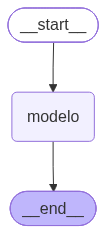

In [17]:
from IPython.display import Image, display
from langgraph.graph import END, START, StateGraph


def modelo(s: MessagesState) -> dict:
    """Toma una muestra del modelo con (σ) ⁀ s(messages)."""
    return {"messages": [llm_con_herramientas.invoke([SISTEMA] + s["messages"])]}


constructor = StateGraph(MessagesState)
constructor.add_node("modelo", modelo)
constructor.add_edge(START, "modelo")
constructor.add_edge("modelo", END)
grafo = constructor.compile()

display(Image(grafo.get_graph().draw_mermaid_png()))

**Proposición 2.8.** Sea $e \in C$ una entrada cuyos mensajes tienen identificador. Una ejecución del grafo usa dos supersteps y termina en el estado $s_1$ con

$$s_1(\text{messages}) = e \oplus (m),$$

donde $m \sim M\left(\cdot \mid (\sigma) \frown e\right)$.

Como el identificador de $m$ es nuevo, $s_1(\text{messages})$ es $e$ seguida de $m$, y no tiene ningún mensaje de herramienta que no estuviera en $e$.

*Demostración.* En el superstep 0, `START` escribe la entrada: $s_0(\text{messages}) = () \oplus e = e$, por la Proposición 2.4. En el superstep 1 corre el único nodo, `modelo`, que devuelve $(m)$ con $m \sim M(\cdot \mid (\sigma) \frown e)$, y $s_1 = s_0 \oplus \varphi(s_0)$. La arista fija $\texttt{modelo} \to \texttt{END}$ termina la ejecución. El identificador de $m$ es `lc_run--` seguido del identificador de la llamada, que es nuevo, así que no está en $\iota(e)$ y $\oplus$ agrega $m$ al final. El único mensaje nuevo es $m$, de rol ai. $\square$

Si los mensajes de $e$ no tienen identificador, `add_messages` se los asigna en el superstep 0 y la proposición vale para esa $e$ con identificadores.

In [18]:
pedidos = ["Deriva x^2·sen(x)", "Integra 1/(1+x^2)", "Resuelve x^2 - 2 = 0", "¿Cuánto es 2 + 2?"]

for pedido in pedidos:
    final = grafo.invoke({"messages": [HumanMessage(pedido)]})
    ultimo = final["messages"][-1]
    print(f"{pedido}  →  {len(final['messages'])} mensajes")
    print("   tool_calls:", [(p["name"], p["args"]) for p in ultimo.tool_calls])
    print("   contenido: ", repr(ultimo.content))

Deriva x^2·sen(x)  →  2 mensajes
   tool_calls: [('derivar', {'expresion': 'x**2*sin(x)', 'variable': 'x'})]
   contenido:  ''
Integra 1/(1+x^2)  →  2 mensajes
   tool_calls: [('integrar', {'expresion': '1/(1 + x**2)', 'variable': 'x'})]
   contenido:  ''
Resuelve x^2 - 2 = 0  →  2 mensajes
   tool_calls: [('resolver', {'ecuacion': 'x**2 - 2', 'variable': 'x'})]
   contenido:  ''
¿Cuánto es 2 + 2?  →  2 mensajes
   tool_calls: []
   contenido:  '2 + 2 es igual a 4.'


Cada ejecución termina con 2 mensajes, el pedido y la respuesta del modelo, como dice la Proposición 2.8. En las tres primeras, el contenido está vacío y el mensaje trae un pedido de herramienta que nadie responde. Para resolver, el modelo escribió `x**2 - 2` sin el «= 0», como permite la descripción del argumento. En la cuarta no pide herramientas y responde con texto.

Un pedido en dos pasos, donde el segundo usa el resultado del primero:

In [19]:
final = grafo.invoke({"messages": [HumanMessage("Deriva x³ y después integra el resultado")]})
[(p["name"], p["args"]) for p in final["messages"][-1].tool_calls]

[('derivar', {'expresion': 'x**3', 'variable': 'x'})]

El modelo pide solo `derivar`. Para integrar el resultado tiene que conocerlo, y eso exige ejecutar la herramienta y volver a llamar al modelo con el resultado: el ciclo de la lección 4. En otra ejecución, con la misma conversación y $T = 0$, el mismo modelo pidió en un solo mensaje `derivar` con `x**3` e `integrar` con `x**3`, así que integró $x^3$ y no su derivada. Un mensaje puede traer varios pedidos, pero todos se escriben antes de conocer cualquier resultado.

Para responder un pedido hay que hacer lo que dice la Definición 2.6: calcular $f_n(x)$ y escribir un `ToolMessage` con el identificador $\gamma$. Hecho a mano:

In [20]:
POR_NOMBRE = {h.__name__: h for h in HERRAMIENTAS}

final = grafo.invoke({"messages": [HumanMessage("Deriva x^2·sen(x)")]})
p = final["messages"][-1].tool_calls[0]
resultado = ToolMessage(POR_NOMBRE[p["name"]](**p["args"]), tool_call_id=p["id"])

for m in add_messages(final["messages"], resultado):
    print(m.pretty_repr())

================================ Human Message =================================

Deriva x^2·sen(x)
================================== Ai Message ==================================
Tool Calls:
  derivar (76787bc9-97d4-402f-be5f-d53d6528c3cd)
 Call ID: 76787bc9-97d4-402f-be5f-d53d6528c3cd
  Args:
    expresion: x**2*sin(x)
    variable: x
================================= Tool Message =================================

x**2*cos(x) + 2*x*sin(x)


Ese paso es el que hace el nodo `tools` de la lección 3, y devolverle el resultado al modelo es el ciclo del agente de la lección 4.

### Profundización 2.A · Un `tool_call` es texto

El modelo no tiene una salida especial para pedir herramientas: escribe texto. Ollama arma ese texto en dos pasos, con una plantilla y un lector.

**Definición 2.A.1.** Sea $\Sigma^*$ el conjunto de textos y $\mathcal{M}_0$ el de los mensajes sin identificadores, ni el del mensaje ni los de sus pedidos. Fijados los esquemas $(n, d, E)$ de las herramientas enlazadas, la plantilla es una función $\tau : \mathcal{M}^* \to \Sigma^*$ que convierte en un texto la sucesión que recibe el modelo, con el mensaje de sistema al comienzo. El modelo propiamente tal es un núcleo $P(\cdot \mid t)$ sobre $\Sigma^*$. El lector es una función $\pi : \Sigma^* \to \mathcal{M}_0 \cup \{\bot\}$ que separa los bloques `<tool_call>` del resto del texto y los convierte en pedidos; $\bot$ indica un texto que no se pudo leer, por ejemplo con un JSON mal formado.

Si $M_0(\cdot \mid c)$ denota la distribución del resultado de una llamada, $\bot$ o $m \sim M(\cdot \mid c)$ sin sus identificadores, entonces $M_0$ es la imagen de $P$ por $\pi$:

$$M_0(B \mid c) = P\left(\pi^{-1}(B) \mid \tau(c)\right)$$

para todo $B \subseteq \mathcal{M}_0 \cup \{\bot\}$.

$\tau$ y $\pi$ son funciones fijas, así que la aleatoriedad del contenido está toda en $P$. Los identificadores se agregan después y al azar: el texto no trae ninguno, y `langchain-ollama` le pone a cada pedido un UUID nuevo. La función $f$ de una herramienta no aparece en ningún lado: $\tau$ usa solo $(n, d, E)$, y $\pi$ produce un pedido sin ejecutarlo. Esta es la parte de la plantilla de `qwen3:8b` que inserta los esquemas:

In [21]:
plantilla = subprocess.run(["ollama", "show", "qwen3:8b", "--template"], capture_output=True, text=True).stdout
inicio = plantilla.index("# Tools")
print(plantilla[inicio : plantilla.index("{{- end -}}", inicio)])

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{{- range .Tools }}
{"type": "function", "function": {{ .Function }}}
{{- end }}
</tools>

For each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:
<tool_call>
{"name": <function-name>, "arguments": <args-json-object>}
</tool_call>



El final de la plantilla, que no está en el fragmento, agrega « /no_think» al último mensaje del usuario y un bloque `<think>` vacío cuando el razonamiento está apagado. Con una copia a mano de $\tau$, con los esquemas en el formato del cliente de Ollama, y la API de Ollama en modo crudo (`raw`), que no aplica plantilla ni lector, se ve el texto que escribe el modelo antes de $\pi$:

In [22]:
def ollama(ruta: str, cuerpo: dict) -> dict:
    pedido = urllib.request.Request(
        "http://127.0.0.1:11434" + ruta,
        data=json.dumps(cuerpo).encode(),
        headers={"Content-Type": "application/json"},
    )
    return json.loads(urllib.request.urlopen(pedido).read())


from ollama import Tool


def esquema_ollama(h) -> str:
    """El esquema de h en el formato del cliente de Ollama, que no tiene `default`."""
    funcion = Tool.model_validate(convert_to_openai_tool(h)).function
    return '{"type": "function", "function": ' + funcion.model_dump_json(exclude_none=True) + "}"


esquemas = "\n".join(esquema_ollama(h) for h in HERRAMIENTAS)
texto = (
    f"<|im_start|>system\n\n{SISTEMA.content}\n\n# Tools\n\n"
    "You may call one or more functions to assist with the user query.\n\n"
    f"You are provided with function signatures within <tools></tools> XML tags:\n<tools>\n{esquemas}\n</tools>\n\n"
    "For each function call, return a json object with function name and arguments within "
    '<tool_call></tool_call> XML tags:\n<tool_call>\n{"name": <function-name>, "arguments": <args-json-object>}\n'
    "</tool_call><|im_end|>\n"
    "<|im_start|>user\nDeriva x^2·sen(x) /no_think<|im_end|>\n"
    "<|im_start|>assistant\n<think>\n\n</think>\n\n"
)
crudo = ollama("/api/generate", {"model": "qwen3:8b", "raw": True, "stream": False, "prompt": texto, "options": {"temperature": 0}})
print(crudo["response"])

<tool_call>
{"name": "derivar", "arguments": {"expresion": "x**2*sin(x)", "variable": "x"}}
</tool_call>


Es el texto que $\pi$ convierte en el pedido de la sección 5: el nombre y los argumentos salen del JSON entre las marcas `<tool_call>`, y el identificador se agrega después. Para el modelo, pedir una herramienta es escribir ese texto, y nada lo obliga a escribirlo bien: un JSON mal formado o un argumento que no cumple $E$ se descubren recién al leerlo o al ejecutar la herramienta.

## Resumen

- Un **mensaje** es un triple $(\rho, \kappa, \iota)$ y una **conversación**, una sucesión de mensajes con identificadores distintos: un diccionario ordenado de identificadores en mensajes.
- `add_messages` es la operación $\oplus$ sobre conversaciones: reemplaza en su lugar los mensajes con identificador repetido y agrega al final los nuevos. $(C, \oplus)$ es un monoide idempotente no conmutativo, igual que `{**d, **e}`. A un mensaje sin identificador le asigna uno al azar, y `RemoveMessage` vuelve parcial la operación.
- `MessagesState` es el esquema con `messages: Annotated[list[AnyMessage], add_messages]`.
- Una **herramienta** es $(n, d, E, f)$. El modelo recibe $(n, d, E)$, armado desde el nombre, el docstring y los tipos de la función; nunca recibe $f$. Un **pedido de herramienta** es $(n, x, \gamma)$, y nada comprueba aún que $x$ cumpla $E$.
- Un modelo de chat es un **núcleo** $M(\cdot \mid c)$, no una función. Con `temperature=0` el contenido casi siempre se repite, pero cada mensaje trae identificadores nuevos.
- El grafo $\texttt{START} \to \texttt{modelo} \to \texttt{END}$ termina en $e \oplus (m)$: el pedido de herramienta queda sin responder, porque ningún nodo ejecuta herramientas (Proposición 2.8). La lección 3 agrega ese nodo.
- Un `tool_call` es texto: salvo los identificadores, $M$ es la imagen por un lector $\pi$ del núcleo $P$ sobre textos, aplicado a la plantilla $\tau(c)$ (Profundización 2.A).

## Ejercicios

**Ejercicio 1 (borrar).** Encontrar conversaciones $a, b$ y un borrado $c = (\texttt{RemoveMessage}(\iota))$ tales que $(a \oplus b) \oplus c$ esté definida y $a \oplus (b \oplus c)$ lance `ValueError`.

*Pista:* el borrado tiene que encontrar su mensaje en $a \oplus b$, pero no en $b$.

<details>
<summary>Solución</summary>

```python
from langchain_core.messages import RemoveMessage

x, y = AIMessage("x", id="x"), AIMessage("y", id="y")
c_borrar = [RemoveMessage(id="x")]

print(ver(add_messages(add_messages([x], [y]), c_borrar)))  # [('y', 'y')]
try:
    add_messages([x], add_messages([y], c_borrar))
except ValueError as error:
    print(error)
```

Con $a = (x)$, $b = (y)$ y $c$ el borrado de $x$: $(a \oplus b) \oplus c = (y)$, pero $b \oplus c$ intenta borrar $x$ de $(y)$ y lanza `ValueError`. Con borrados, $\oplus$ es una operación parcial, y la asociatividad solo puede pedirse cuando los dos lados están definidos.

</details>

**Ejercicio 2 (cuándo conmuta).** Demostrar que $a \oplus b = b \oplus a$ si y solo si una de las sucesiones $\iota(a)$, $\iota(b)$ es prefijo de la otra y $a$, $b$ tienen el mismo mensaje en cada identificador común. Comprobarlo con las conversaciones del universo de la sección 3.

*Pista:* $\iota(a) \cdot \iota(b)$ empieza con $\iota(a)$, e $\iota(b) \cdot \iota(a)$ empieza con $\iota(b)$.

<details>
<summary>Solución</summary>

($\Leftarrow$) Si $A = \iota(a)$ es prefijo de $B = \iota(b)$, entonces $A \cdot B = B$ y $B \cdot A = B$. En los identificadores comunes, que son los de $A$, $a$ y $b$ tienen el mismo mensaje, así que da igual cuál gane. El caso con $B$ prefijo de $A$ es simétrico.

($\Rightarrow$) Si $a \oplus b = b \oplus a$, la sucesión de identificadores común empieza con $A$ y con $B$, así que la más corta de las dos es prefijo de la otra. En cada identificador común, $a \oplus b$ tiene el mensaje de $b$ y $b \oplus a$ el de $a$; como son iguales, $a$ y $b$ coinciden ahí.

```python
def es_prefijo(u: list, v: list) -> bool:
    return v[: len(u)] == u


def conmutan_segun_criterio(x: list, y: list) -> bool:
    ix, iy = [m.id for m in x], [m.id for m in y]
    dx, dy = dict(ver(x)), dict(ver(y))
    comunes_iguales = all(dx[i] == dy[i] for i in dx.keys() & dy.keys())
    return (es_prefijo(ix, iy) or es_prefijo(iy, ix)) and comunes_iguales


all(
    (ver(add_messages(x, y)) == ver(add_messages(y, x))) == conmutan_segun_criterio(x, y)
    for x in conversaciones
    for y in conversaciones
)  # True
```

</details>

**Ejercicio 3 (una cuarta herramienta).** Escribir `limite(expresion, punto, variable="x")` con `sympy.limit`, ver su esquema con `convert_to_openai_tool` y calcular $\lim_{x \to 0} \frac{\sin x}{x}$ y $\lim_{x \to \infty} \left(1 + \frac{1}{x}\right)^x$. ¿Qué argumentos quedan obligatorios? En Kaggle, enlazarla al modelo junto a las otras tres y pedirle uno de esos límites.

*Pista:* en SymPy, el infinito es `oo`, y `leer("oo")` lo entiende.

<details>
<summary>Solución</summary>

```python
from sympy import limit


def limite(expresion: str, punto: str, variable: str = "x") -> str:
    """Calcula el límite de una expresión cuando la variable tiende a un punto.

    Args:
        expresion: expresión en sintaxis de SymPy, por ejemplo sin(x)/x.
        punto: punto al que tiende la variable; oo es infinito.
        variable: variable que tiende al punto.
    """
    return str(limit(leer(expresion), Symbol(variable), leer(punto)))


print(limite("sin(x)/x", "0"))        # 1
print(limite("(1 + 1/x)**x", "oo"))   # E
print(convert_to_openai_tool(limite)["function"]["parameters"]["required"])  # ['expresion', 'punto']
```

Quedan obligatorios `expresion` y `punto`, los argumentos sin valor por defecto. Con el modelo: `llm.bind_tools(HERRAMIENTAS + [limite]).invoke([SISTEMA, HumanMessage("¿Cuál es el límite de sen(x)/x cuando x tiende a 0?")]).tool_calls`.

</details>

**Ejercicio 4 (el docstring es la interfaz).** Copiar `derivar` sin la sección `Args` y, después, sin docstring. Comparar los tres esquemas. ¿Qué deja de saber el modelo en cada caso?

*Pista:* `convert_to_openai_tool` no falla sin docstring.

<details>
<summary>Solución</summary>

```python
def derivar_sin_args(expresion: str, variable: str = "x") -> str:
    """Deriva una expresión respecto de una variable."""
    return derivar(expresion, variable)


def derivar_sin_docstring(expresion: str, variable: str = "x") -> str:
    return derivar(expresion, variable)


for funcion in (derivar, derivar_sin_args, derivar_sin_docstring):
    esquema = convert_to_openai_tool(funcion)["function"]
    print(esquema["name"], "|", repr(esquema["description"]), "|", esquema["parameters"]["properties"])
```

Sin `Args`, los argumentos pierden su descripción: el modelo ya no sabe que `expresion` va en sintaxis de SymPy ni qué es `variable`. Sin docstring, además la descripción de la herramienta queda vacía, y el modelo solo tiene el nombre y los tipos para decidir cuándo usarla.

</details>

**Ejercicio 5 (cuántas muestras).** Se fijan una conversación $c$ y una temperatura, y se llama $N$ veces al modelo con herramientas. Sea $p$ la probabilidad de que $M(\cdot \mid c)$ pida `derivar`, y $\hat p$ la fracción de las $N$ muestras que lo piden, suponiendo muestras independientes. La desigualdad de Hoeffding da $P(|\hat p - p| \ge t) \le 2e^{-2Nt^2}$. Con una confianza de 95 %, ¿qué error $t$ garantizan 10 muestras, tantas como en el experimento de la sección 5? ¿Cuántas hacen falta para $t = 0{,}05$?

*Pista:* despejar $t$ de $2e^{-2Nt^2} = 0{,}05$.

<details>
<summary>Solución</summary>

De $2e^{-2Nt^2} = 0{,}05$ sale $t = \sqrt{\ln 40 / (2N)}$. Para $t = 0{,}05$ hace falta $N \ge \ln 40 / (2 \cdot 0{,}05^2) \approx 737{,}8$.

```python
import math

print(math.sqrt(math.log(40) / (2 * 10)))       # 0.429...
print(math.ceil(math.log(40) / (2 * 0.05**2)))  # 738
```

Con 10 muestras, el error garantizado es $t \approx 0{,}43$: un experimento de ese tamaño, como el de la sección 5, muestra que hay variación, pero no alcanza para estimar probabilidades. Para un error de 5 puntos con 95 % de confianza hacen falta 738 muestras.

</details>